# Adathalmaz betöltése és feltárása

In [19]:
%pip install tensorflow numpy pandas matplotlib seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from pathlib import Path
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Seaborn version:", sns.__version__)

TensorFlow version: 2.22.0-rc0
NumPy version: 2.4.4
Pandas version: 3.0.2
Matplotlib version: 3.10.8
Seaborn version: 0.13.2


In [21]:
DATASET_PATH = Path("../dataset/brand")

CLASSES = ["nike", "adidas", "converse"]

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_counts = {}

for brand in CLASSES:
    folder = DATASET_PATH / brand

    images = [
        file for file in folder.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    image_counts[brand] = len(images)

df = pd.DataFrame(
    list(image_counts.items()),
    columns=["Brand", "Image Count"]
)

print(df)
print("\nTotal images:", df["Image Count"].sum())

      Brand  Image Count
0      nike          195
1    adidas          210
2  converse          195

Total images: 600


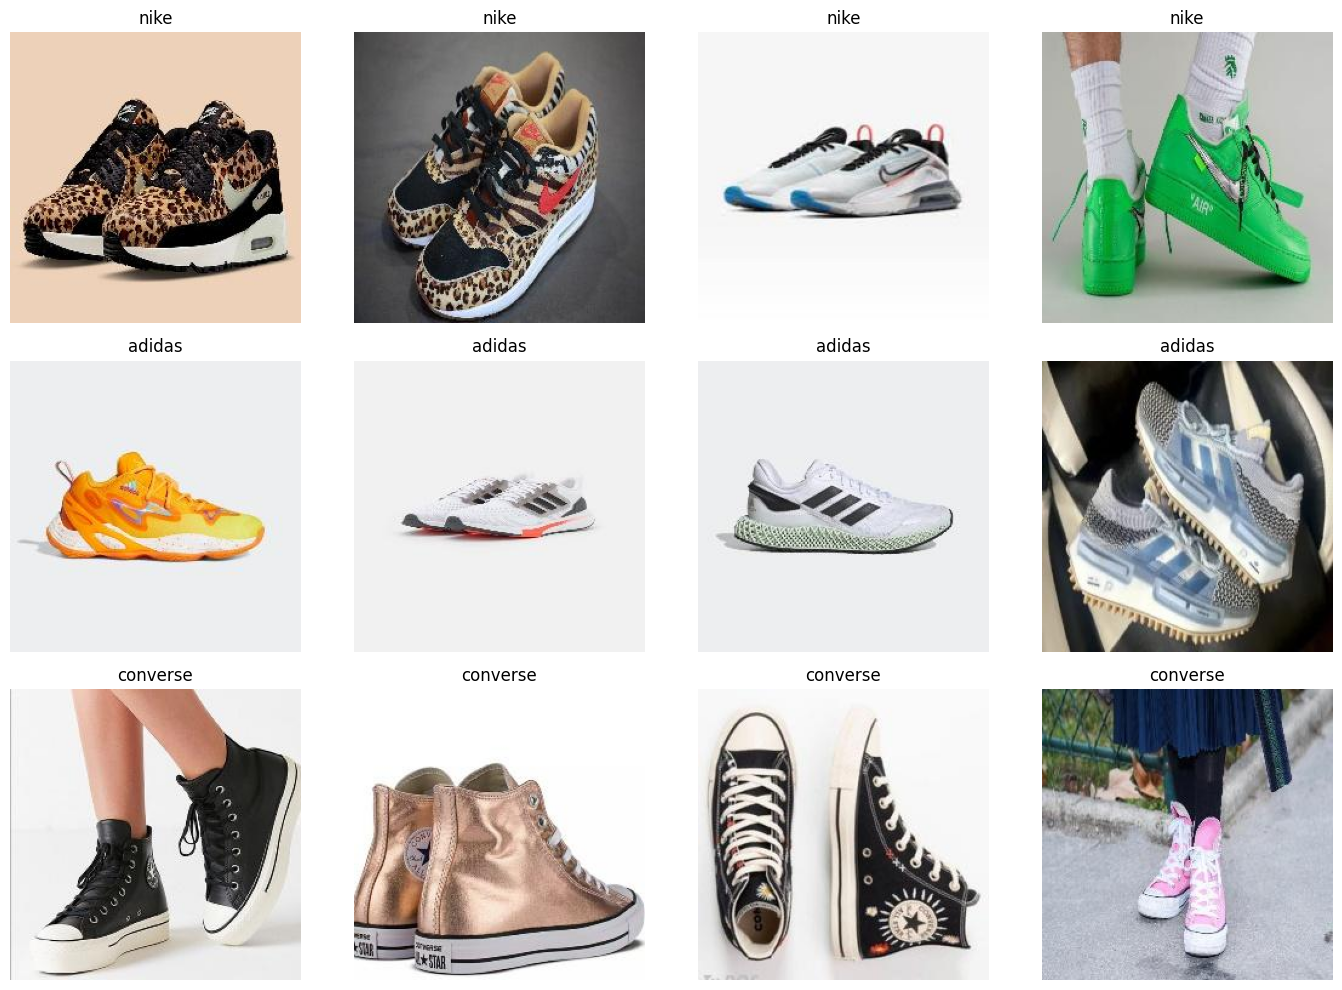

In [22]:
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

for row, brand in enumerate(CLASSES):

    folder = DATASET_PATH / brand

    images = [
        file for file in folder.iterdir()
        if file.suffix.lower() in image_extensions
    ]

    selected = np.random.choice(
        images,
        min(4, len(images)),
        replace=False
    )

    for col, image_path in enumerate(selected):

        img = Image.open(image_path).convert("RGB")

        axes[row, col].imshow(img)
        axes[row, col].set_title(brand)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [23]:
image_data = []

for brand in CLASSES:

    folder = DATASET_PATH / brand

    for image_path in folder.iterdir():

        if image_path.suffix.lower() not in image_extensions:
            continue

        try:
            with Image.open(image_path) as img:

                image_data.append({
                    "Brand": brand,
                    "Width": img.width,
                    "Height": img.height,
                    "Format": img.format
                })

        except Exception:
            print("Invalid image:", image_path)

image_df = pd.DataFrame(image_data)

display(image_df.groupby("Brand")[["Width", "Height"]].describe())

Width                                                Height         \
          count   mean  std    min    25%    50%    75%    max  count   mean   
Brand                                                                          
adidas    210.0  240.0  0.0  240.0  240.0  240.0  240.0  240.0  210.0  240.0   
converse  195.0  240.0  0.0  240.0  240.0  240.0  240.0  240.0  195.0  240.0   
nike      195.0  240.0  0.0  240.0  240.0  240.0  240.0  240.0  195.0  240.0   

                                                  
          std    min    25%    50%    75%    max  
Brand                                             
adidas    0.0  240.0  240.0  240.0  240.0  240.0  
converse  0.0  240.0  240.0  240.0  240.0  240.0  
nike      0.0  240.0  240.0  240.0  240.0  240.0